# Ejemplo: algoritmo genético paso a paso

**Objetivo:** identificar cómo un algoritmo genético encuentra valores cada vez mejores.

No necesitas escribir código. **Solo cambia el número de lista en la siguiente celda** y ejecuta las celdas de arriba hacia abajo (▶). No modifiques el resto.

In [1]:
# ✏️ ÚNICO DATO QUE DEBES CAMBIAR
NUMERO_LISTA = 12  # Sustituye 12 por tu número de lista (1 a 50)

assert isinstance(NUMERO_LISTA, int) and 1 <= NUMERO_LISTA <= 50, "Introduce un entero del 1 al 50"
print(f"Número de lista: {NUMERO_LISTA}")

Número de lista: 12


## 1. El problema: encontrar el mínimo
Partimos de una función muy fácil de comprender:

\[f(x)=(x-a)^2\]

- **x** es una posible solución.
- **a** es la posición del mínimo, que cambia según el número de lista.
- Queremos **minimizar**: cuanto menor sea \(f(x)\), mejor será la solución.

En este ejercicio, \(a=4+0.1N\), donde \(N\) es tu número de lista. Trabajaremos con valores de \(x\) entre 0 y 10.

**Importante:** conocemos el mínimo matemático para comprobar los resultados, pero el algoritmo no recibe directamente ese valor. Solo evalúa la función para las soluciones candidatas.

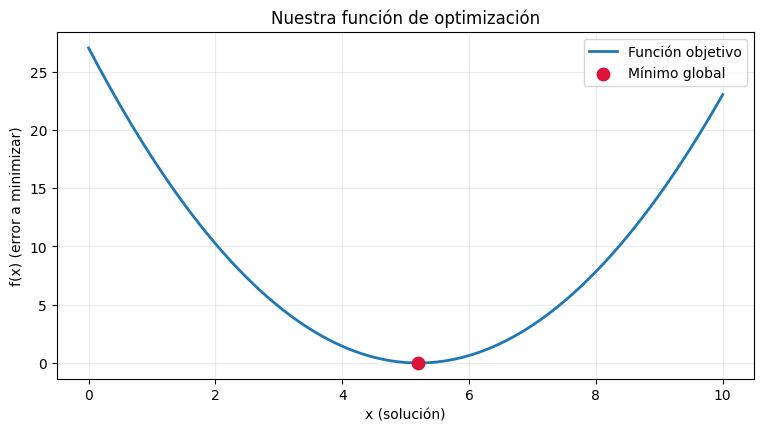

Función de tu ejercicio: f(x) = (x - 5.20)²
Mínimo matemático conocido: x = 5.20, f(x) = 0


In [2]:
import numpy as np
import matplotlib.pyplot as plt

objetivo = 4 + 0.1 * NUMERO_LISTA

def funcion(x):
    return (np.asarray(x) - objetivo)**2

x = np.linspace(0, 10, 500)
plt.figure(figsize=(9,4.5))
plt.plot(x, funcion(x), label='Función objetivo', linewidth=2)
plt.scatter([objetivo], [0], color='crimson', s=80, zorder=5, label='Mínimo global')
plt.xlabel('x (solución)')
plt.ylabel('f(x) (error a minimizar)')
plt.title('Nuestra función de optimización')
plt.legend(); plt.grid(alpha=0.25); plt.show()
print(f"Función de tu ejercicio: f(x) = (x - {objetivo:.2f})²")
print(f"Mínimo matemático conocido: x = {objetivo:.2f}, f(x) = 0")

## 2. Generación inicial: varios individuos
Un **individuo** es un número \(x\) que podría resolver el problema. Una **población** es un conjunto de individuos.

Usaremos **6 individuos** iniciales. El **fitness** será el valor \(f(x)\): **como queremos minimizar, menor fitness significa mejor individuo**.

Para que cada alumno pueda reproducir su ejecución, el número de lista fija también la semilla aleatoria.

In [3]:
rng = np.random.default_rng(1000 + NUMERO_LISTA)
TAMANO_POBLACION = 6
poblacion_inicial = rng.uniform(0,10,TAMANO_POBLACION)

def mostrar_tabla(poblacion, titulo):
    print('\n'+titulo)
    print('Individuo |       x |  fitness f(x)')
    print('----------+---------+-------------')
    for i, xi in enumerate(poblacion, 1):
        print(f'{i:^9} | {xi:7.3f} | {float(funcion(xi)):11.4f}')

mostrar_tabla(poblacion_inicial, 'POBLACIÓN INICIAL')
mejor_idx = int(np.argmin(funcion(poblacion_inicial)))
print(f'\nMejor individuo inicial: #{mejor_idx+1}, x={poblacion_inicial[mejor_idx]:.3f}, fitness={funcion(poblacion_inicial[mejor_idx]):.4f}')


POBLACIÓN INICIAL
Individuo |       x |  fitness f(x)
----------+---------+-------------
    1     |   3.063 |      4.5659
    2     |   7.806 |      6.7937
    3     |   2.384 |      7.9278
    4     |   8.604 |     11.5873
    5     |   4.937 |      0.0690
    6     |   6.652 |      2.1079

Mejor individuo inicial: #5, x=4.937, fitness=0.0690


## 3. ¿Cómo se crea una nueva generación?
En cada generación ocurren estas operaciones:

1. **Selección por torneo:** se toman al azar dos individuos y gana el de menor fitness. Se repite para elegir al otro padre.
2. **Cruce aritmético:** se combinan los números de los padres con \(h=lpha p_1+(1-lpha)p_2\), usando un \(lpha\) aleatorio entre 0 y 1.
3. **Mutación gaussiana:** algunas veces se suma un pequeño número aleatorio al hijo, \(h'=h+arepsilon\).
4. **Elitismo:** los dos mejores individuos de la generación anterior pasan sin cambios a la siguiente.

Parámetros del ejemplo: **probabilidad de mutación = 30 %**, **desviación de mutación = 0.38**, **elitismo = 2**. No hay que cambiarlos.

En la siguiente celda puedes leer los detalles de **una generación**. Las elecciones aleatorias pueden generar hijos peores; por eso conservamos élites.

In [4]:
PROBABILIDAD_MUTACION = 0.30
DESVIACION_MUTACION = 0.38
ELITISMO = 2

def elegir_por_torneo(poblacion, rng):
    indices = rng.choice(len(poblacion), size=2, replace=False)
    ganador = int(indices[np.argmin(funcion(poblacion[indices]))])
    return float(poblacion[ganador]), indices, ganador

def siguiente_generacion(poblacion, rng, detallar=False):
    orden = np.argsort(funcion(poblacion))
    nueva = [float(poblacion[i]) for i in orden[:ELITISMO]]
    if detallar:
        print('ELITISMO: conservamos directamente:')
        for i in orden[:ELITISMO]:
            print(f'  individuo #{i+1}: x={poblacion[i]:.3f}, fitness={funcion(poblacion[i]):.4f}')
    hijo_n = 0
    while len(nueva) < len(poblacion):
        p1, part1, g1 = elegir_por_torneo(poblacion, rng)
        p2, part2, g2 = elegir_por_torneo(poblacion, rng)
        alpha = float(rng.uniform(0,1))
        hijo = alpha*p1+(1-alpha)*p2
        antes = hijo
        mutacion = bool(rng.random()<PROBABILIDAD_MUTACION)
        perturbacion = float(rng.normal(0,DESVIACION_MUTACION)) if mutacion else 0.0
        hijo = float(np.clip(hijo+perturbacion,0,10))
        nueva.append(hijo)
        hijo_n+=1
        if detallar:
            print(f'\nHijo {hijo_n}:')
            print(f'  Torneo padre 1: #{part1[0]+1} vs #{part1[1]+1}; ganó #{g1+1}, x={p1:.3f}')
            print(f'  Torneo padre 2: #{part2[0]+1} vs #{part2[1]+1}; ganó #{g2+1}, x={p2:.3f}')
            print(f'  Cruce: α={alpha:.3f} -> hijo={antes:.3f}')
            print(f'  Mutación: {"sí" if mutacion else "no"}; cambio={perturbacion:+.3f} -> x final={hijo:.3f}')
    return np.array(nueva)

rng_ejemplo = np.random.default_rng(2000+NUMERO_LISTA)
poblacion_segunda = siguiente_generacion(poblacion_inicial,rng_ejemplo,detallar=True)
mostrar_tabla(poblacion_segunda,'POBLACIÓN DESPUÉS DE UNA GENERACIÓN')

ELITISMO: conservamos directamente:
  individuo #5: x=4.937, fitness=0.0690
  individuo #6: x=6.652, fitness=2.1079

Hijo 1:
  Torneo padre 1: #2 vs #5; ganó #5, x=4.937
  Torneo padre 2: #6 vs #1; ganó #6, x=6.652
  Cruce: α=0.286 -> hijo=6.162
  Mutación: no; cambio=+0.000 -> x final=6.162

Hijo 2:
  Torneo padre 1: #4 vs #5; ganó #5, x=4.937
  Torneo padre 2: #6 vs #2; ganó #6, x=6.652
  Cruce: α=0.066 -> hijo=6.539
  Mutación: no; cambio=+0.000 -> x final=6.539

Hijo 3:
  Torneo padre 1: #4 vs #2; ganó #2, x=7.806
  Torneo padre 2: #5 vs #2; ganó #5, x=4.937
  Cruce: α=0.152 -> hijo=5.374
  Mutación: sí; cambio=-0.236 -> x final=5.138

Hijo 4:
  Torneo padre 1: #4 vs #1; ganó #1, x=3.063
  Torneo padre 2: #2 vs #1; ganó #1, x=3.063
  Cruce: α=0.303 -> hijo=3.063
  Mutación: no; cambio=+0.000 -> x final=3.063

POBLACIÓN DESPUÉS DE UNA GENERACIÓN
Individuo |       x |  fitness f(x)
----------+---------+-------------
    1     |   4.937 |      0.0690
    2     |   6.652 |      2.1079


## 4. Evolución y convergencia
Ahora el mismo algoritmo se ejecuta automáticamente durante **35 generaciones**. Observaremos dos tipos de gráficas:

- **Poblaciones sobre la función:** cada punto representa un individuo. Permite ver cómo cambia la ubicación de las soluciones.
- **Curva de convergencia:** registra el menor fitness de cada generación. Como minimizamos, queremos que descienda hacia cero.

**Convergencia** es el comportamiento por el cual las soluciones o sus resultados se acercan progresivamente a un valor. Una curva horizontal no demuestra por sí sola que alcanzamos el mínimo global.

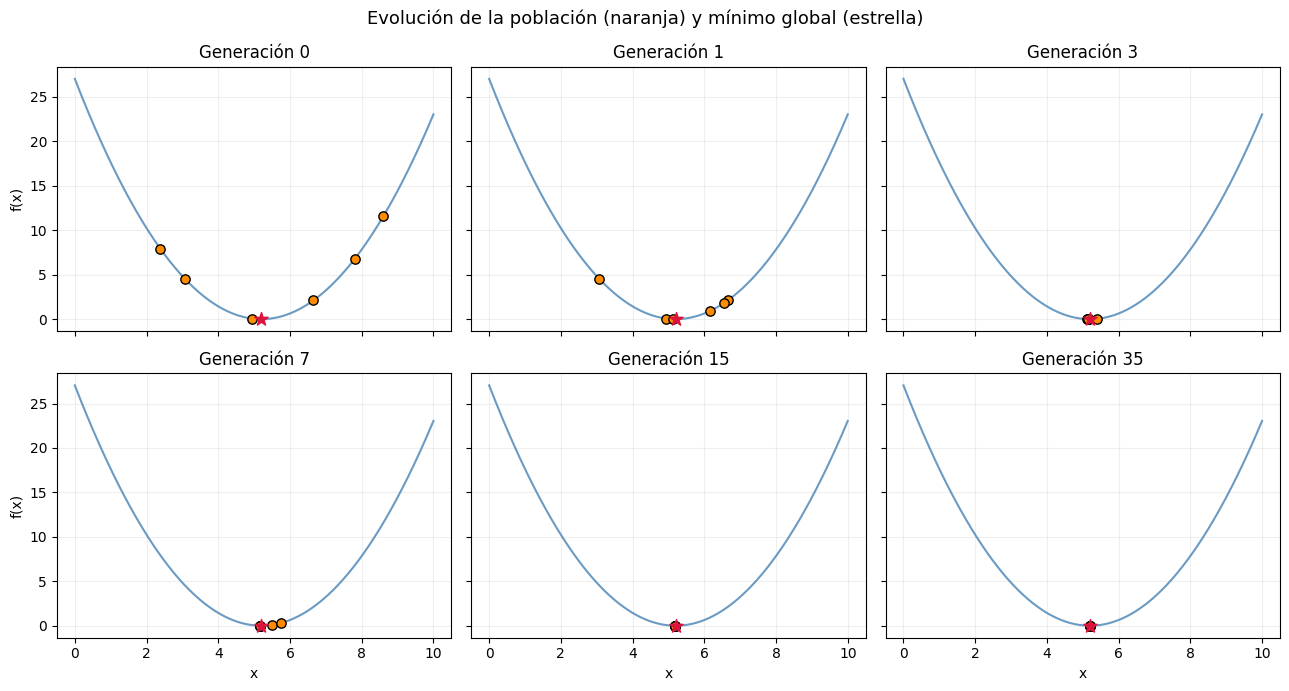

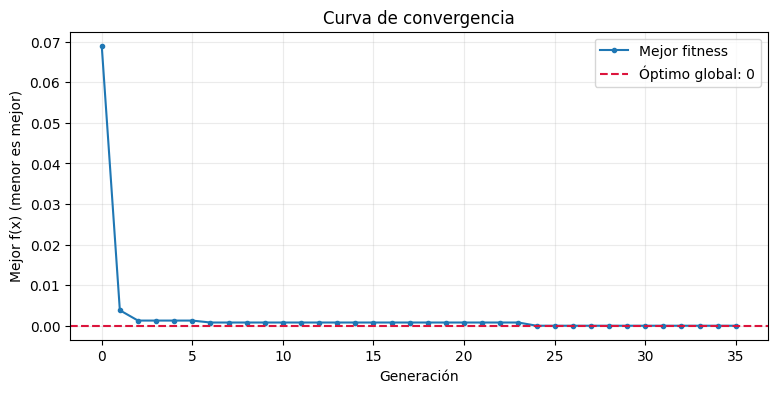

Mejor solución encontrada: x=5.19956
Fitness final: 0.00000019
Mínimo conocido: x=5.20000, f(x)=0
Distancia al mínimo conocido: 0.000436


In [5]:
rng_simulacion = np.random.default_rng(2000+NUMERO_LISTA)
poblacion = poblacion_inicial.copy()
NUM_GENERACIONES = 35
historial = [poblacion.copy()]
mejores = [float(np.min(funcion(poblacion)))]
for _ in range(NUM_GENERACIONES):
    poblacion = siguiente_generacion(poblacion, rng_simulacion)
    historial.append(poblacion.copy())
    mejores.append(float(np.min(funcion(poblacion))))

fig, axes = plt.subplots(2,3,figsize=(13,7),sharex=True,sharey=True)
for ax,gen in zip(axes.flat,[0,1,3,7,15,35]):
    ax.plot(x, funcion(x),color='steelblue',alpha=.8)
    p=historial[gen]
    ax.scatter(p, funcion(p), color='darkorange', edgecolor='black',s=45,zorder=5)
    ax.scatter([objetivo],[0],color='crimson', marker='*', s=100,zorder=6)
    ax.set_title(f'Generación {gen}');ax.grid(alpha=.2)
for ax in axes[-1]: ax.set_xlabel('x')
for ax in axes[:,0]: ax.set_ylabel('f(x)')
plt.suptitle('Evolución de la población (naranja) y mínimo global (estrella)',fontsize=13)
plt.tight_layout();plt.show()

plt.figure(figsize=(9,4))
plt.plot(range(NUM_GENERACIONES+1), mejores,marker='o',markersize=3,label='Mejor fitness')
plt.axhline(0,color='crimson',linestyle='--',label='Óptimo global: 0')
plt.xlabel('Generación');plt.ylabel('Mejor f(x) (menor es mejor)')
plt.title('Curva de convergencia');plt.legend();plt.grid(alpha=.25);plt.show()

posicion_final = float(poblacion[np.argmin(funcion(poblacion))])
print(f'Mejor solución encontrada: x={posicion_final:.5f}')
print(f'Fitness final: {float(funcion(posicion_final)):.8f}')
print(f'Mínimo conocido: x={objetivo:.5f}, f(x)=0')
print(f'Distancia al mínimo conocido: {abs(posicion_final-objetivo):.6f}')

## 5. Responde con tus palabras (no es un ejercicio de programación)

**Anota tus respuestas debajo de cada pregunta.** Puedes apoyarte en los números y las gráficas de tu propia ejecución.

1. ¿Cuál es la función objetivo de tu ejercicio y qué número de lista utilizaste?  
   **Respuesta:**

2. ¿Cuál es el valor de \(x\) que minimiza matemáticamente tu función? ¿Cuál es el valor mínimo de \(f(x)\)?  
   **Respuesta:**

3. En tu población inicial, ¿qué individuo tuvo el menor fitness? Explica por qué es el mejor.  
   **Respuesta:**

4. En el ejemplo detallado, ¿qué significa que un padre gane un torneo?  
   **Respuesta:**

5. Elige un hijo del ejemplo detallado y explica cómo se formó por cruce y si recibió mutación.  
   **Respuesta:**

6. ¿Por qué se conservaron dos individuos mediante elitismo?  
   **Respuesta:**

7. ¿El mejor fitness disminuyó, aumentó o permaneció igual durante las generaciones? Describe la curva de convergencia.  
   **Respuesta:**

8. ¿El algoritmo encontró exactamente el mínimo global o solo se aproximó? Justifica con los valores finales.  
   **Respuesta:**

**Reflexión:** si modificáramos la probabilidad de mutación, ¿qué comportamiento esperarías observar y por qué?  
**Respuesta:**